In [2]:
import pandas as pd

df = pd.read_csv("../dataset/commodity_trade_statistics_data.csv")
df.head()

C:\Users\arman\AppData\Local\Temp\ipykernel_22820\994003978.py:3: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../dataset/commodity_trade_statistics_data.csv")


,country_or_area,year,comm_code,commodity,flow,trade_usd,weight_kg,quantity_name,quantity,category
0,Afghanistan,2016,10410,"Sheep, live",Export,6088,2339.0,Number of items,51.0,01_live_animals
1,Afghanistan,2016,10420,"Goats, live",Export,3958,984.0,Number of items,53.0,01_live_animals
2,Afghanistan,2008,10210,"Bovine animals, live pure-bred breeding",Import,1026804,272.0,Number of items,3769.0,01_live_animals
3,Albania,2016,10290,"Bovine animals, live, except pure-bred breeding",Import,2414533,1114023.0,Number of items,6853.0,01_live_animals
4,Albania,2016,10392,"Swine, live except pure-bred breeding > 50 kg",Import,14265937,9484953.0,Number of items,96040.0,01_live_animals


In [3]:
# Overview: dtypes, non-null counts, memory
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8225871 entries, 0 to 8225870
Data columns (total 10 columns):
 #   Column           Dtype  
---  ------           -----  
 0   country_or_area  object 
 1   year             int64  
 2   comm_code        object 
 3   commodity        object 
 4   flow             object 
 5   trade_usd        int64  
 6   weight_kg        float64
 7   quantity_name    object 
 8   quantity         float64
 9   category         object 
dtypes: float64(2), int64(2), object(6)
memory usage: 627.6+ MB


In [4]:
# Unique value count per column (cardinality check)
df.nunique()

country_or_area        209
year                    29
comm_code             5047
commodity             5031
flow                     4
trade_usd          3062165
weight_kg          2137907
quantity_name           12
quantity           2124833
category                98
dtype: int64

In [5]:
# Nulls
df.isnull().sum()

country_or_area         0
year                    0
comm_code               0
commodity               0
flow                    0
trade_usd               0
weight_kg          128475
quantity_name           0
quantity           304857
category                0
dtype: int64

In [6]:
df.columns

Index(['country_or_area', 'year', 'comm_code', 'commodity', 'flow',
       'trade_usd', 'weight_kg', 'quantity_name', 'quantity', 'category'],
      dtype='object')

In [7]:
# 1. Drop TOTAL rows
df = df[df['comm_code'] != 'TOTAL'].copy()
print("Shape after removing TOTAL:", df.shape)

print()

# 2. trade_usd sanity check
print("Negative trade_usd:", (df['trade_usd'] < 0).sum())
print("Zero trade_usd:", (df['trade_usd'] == 0).sum())

print()

# 3. Duplicates
print("Full duplicate rows:", df.duplicated().sum())

print()

# 4. category class balance (your classification target)
print(df['category'].value_counts())

print()

# 5. weight_kg / quantity nulls
print(df[['weight_kg', 'quantity']].isnull().sum())

Shape after removing TOTAL: (8216686, 10)

Negative trade_usd: 0
Zero trade_usd: 0

Full duplicate rows: 0

category
02_meat_and_edible_meat_offal                             100000
32_tanning_dyeing_extracts_tannins_derivs_pigments_et     100000
03_fish_crustaceans_molluscs_aquatic_invertebrates_ne     100000
04_dairy_products_eggs_honey_edible_animal_product_nes    100000
07_edible_vegetables_and_certain_roots_and_tubers         100000
                                                           ...  
46_manufactures_of_plaiting_material_basketwork_etc        31954
45_cork_and_articles_of_cork                               31446
14_vegetable_plaiting_materials_vegetable_products_nes     30179
80_tin_and_articles_thereof                                29328
99_commodities_not_specified_according_to_kind              7024
Name: count, Length: 97, dtype: int64

weight_kg    119355
quantity     295737
dtype: int64


In [8]:
# 1. Quantity name unit mismatch check
print("=" * 50)
print("1. QUANTITY UNIT CHECK")
print("=" * 50)
print(df['quantity_name'].value_counts())


# 2. Null %
print("\n" + "=" * 50)
print("2. NULL PERCENTAGE")
print("=" * 50)
print("weight_kg null %:", df['weight_kg'].isnull().mean() * 100)
print("quantity null %:", df['quantity'].isnull().mean() * 100)


# 3. Trade_usd distribution stats
print("\n" + "=" * 50)
print("3. TRADE_USD DISTRIBUTION")
print("=" * 50)
print(df['trade_usd'].describe())


# 4. Drop nulls
print("\n" + "=" * 50)
print("4. HANDLING NULL VALUES")
print("=" * 50)

df = df.dropna(subset=['weight_kg', 'quantity'])

print("Shape after dropping nulls:", df.shape)

1. QUANTITY UNIT CHECK
quantity_name
Weight in kilograms                                 6617980
Number of items                                      709321
No Quantity                                          495991
Volume in litres                                     144599
Area in square metres                                135912
Number of pairs                                       67929
Length in metres                                      18225
Volume in cubic meters                                17775
Weight in carats                                       5237
Thousands of items                                     1386
Electrical energy in thousands of kilowatt-hours       1264
Number of packages                                     1067
Name: count, dtype: int64

2. NULL PERCENTAGE
weight_kg null %: 1.4525929310186612
quantity null %: 3.599224796955853

3. TRADE_USD DISTRIBUTION
count    8.216686e+06
mean     2.402013e+07
std      7.414262e+08
min      1.000000e+00
25%      1

In [9]:
category_group_mapping = {
    # 1. Food, Beverages & Tobacco (01-24)
    "01_live_animals": "Food, Beverages & Tobacco",
    "02_meat_and_edible_meat_offal": "Food, Beverages & Tobacco",
    "03_fish_crustaceans_molluscs_aquatic_invertebrates_ne": "Food, Beverages & Tobacco",
    "04_dairy_products_eggs_honey_edible_animal_product_nes": "Food, Beverages & Tobacco",
    "05_products_of_animal_origin_nes": "Food, Beverages & Tobacco",
    "06_live_trees_plants_bulbs_roots_cut_flowers_etc": "Food, Beverages & Tobacco",
    "07_edible_vegetables_and_certain_roots_and_tubers": "Food, Beverages & Tobacco",
    "08_edible_fruit_nuts_peel_of_citrus_fruit_melons": "Food, Beverages & Tobacco",
    "09_coffee_tea_mate_and_spices": "Food, Beverages & Tobacco",
    "10_cereals": "Food, Beverages & Tobacco",
    "11_milling_products_malt_starches_inulin_wheat_glute": "Food, Beverages & Tobacco",
    "12_oil_seed_oleagic_fruits_grain_seed_fruit_etc_ne": "Food, Beverages & Tobacco",
    "13_lac_gums_resins_vegetable_saps_and_extracts_nes": "Food, Beverages & Tobacco",
    "14_vegetable_plaiting_materials_vegetable_products_nes": "Food, Beverages & Tobacco",
    "15_animal_vegetable_fats_and_oils_cleavage_products_et": "Food, Beverages & Tobacco",
    "16_meat_fish_and_seafood_food_preparations_nes": "Food, Beverages & Tobacco",
    "17_sugars_and_sugar_confectionery": "Food, Beverages & Tobacco",
    "18_cocoa_and_cocoa_preparations": "Food, Beverages & Tobacco",
    "19_cereal_flour_starch_milk_preparations_and_products": "Food, Beverages & Tobacco",
    "20_vegetable_fruit_nut_etc_food_preparations": "Food, Beverages & Tobacco",
    "21_miscellaneous_edible_preparations": "Food, Beverages & Tobacco",
    "22_beverages_spirits_and_vinegar": "Food, Beverages & Tobacco",
    "23_residues_wastes_of_food_industry_animal_fodder": "Food, Beverages & Tobacco",
    "24_tobacco_and_manufactured_tobacco_substitutes": "Food, Beverages & Tobacco",

    # 2. Minerals, Fuels & Ores (25-27)
    "25_salt_sulphur_earth_stone_plaster_lime_and_cement": "Minerals, Fuels & Ores",
    "26_ores_slag_and_ash": "Minerals, Fuels & Ores",
    "27_mineral_fuels_oils_distillation_products_etc": "Minerals, Fuels & Ores",

    # 3. Chemicals & Pharmaceuticals (28-38)
    "28_inorganic_chemicals_precious_metal_compound_isotope": "Chemicals & Pharmaceuticals",
    "29_organic_chemicals": "Chemicals & Pharmaceuticals",
    "30_pharmaceutical_products": "Chemicals & Pharmaceuticals",
    "31_fertilizers": "Chemicals & Pharmaceuticals",
    "32_tanning_dyeing_extracts_tannins_derivs_pigments_et": "Chemicals & Pharmaceuticals",
    "33_essential_oils_perfumes_cosmetics_toileteries": "Chemicals & Pharmaceuticals",
    "34_soaps_lubricants_waxes_candles_modelling_pastes": "Chemicals & Pharmaceuticals",
    "35_albuminoids_modified_starches_glues_enzymes": "Chemicals & Pharmaceuticals",
    "36_explosives_pyrotechnics_matches_pyrophorics_etc": "Chemicals & Pharmaceuticals",
    "37_photographic_or_cinematographic_goods": "Chemicals & Pharmaceuticals",
    "38_miscellaneous_chemical_products": "Chemicals & Pharmaceuticals",

    # 4. Plastics & Rubber (39-40)
    "39_plastics_and_articles_thereof": "Plastics & Rubber",
    "40_rubber_and_articles_thereof": "Plastics & Rubber",

    # 5. Leather, Hides & Furskins (41-43)
    "41_raw_hides_and_skins_other_than_furskins_and_leather": "Leather, Hides & Furskins",
    "42_articles_of_leather_animal_gut_harness_travel_good": "Leather, Hides & Furskins",
    "43_furskins_and_artificial_fur_manufactures_thereof": "Leather, Hides & Furskins",

    # 6. Wood, Paper & Pulp (44-49)
    "44_wood_and_articles_of_wood_wood_charcoal": "Wood, Paper & Pulp",
    "45_cork_and_articles_of_cork": "Wood, Paper & Pulp",
    "46_manufactures_of_plaiting_material_basketwork_etc": "Wood, Paper & Pulp",
    "47_pulp_of_wood_fibrous_cellulosic_material_waste_etc": "Wood, Paper & Pulp",
    "48_paper_paperboard_articles_of_pulp_paper_and_board": "Wood, Paper & Pulp",
    "49_printed_books_newspapers_pictures_etc": "Wood, Paper & Pulp",

    # 7. Textiles & Apparel (50-63)
    "50_silk": "Textiles & Apparel",
    "51_wool_animal_hair_horsehair_yarn_and_fabric_thereof": "Textiles & Apparel",
    "52_cotton": "Textiles & Apparel",
    "53_vegetable_textile_fibres_nes_paper_yarn_woven_fabri": "Textiles & Apparel",
    "54_manmade_filaments": "Textiles & Apparel",
    "55_manmade_staple_fibres": "Textiles & Apparel",
    "56_wadding_felt_nonwovens_yarns_twine_cordage_etc": "Textiles & Apparel",
    "57_carpets_and_other_textile_floor_coverings": "Textiles & Apparel",
    "58_special_woven_or_tufted_fabric_lace_tapestry_etc": "Textiles & Apparel",
    "59_impregnated_coated_or_laminated_textile_fabric": "Textiles & Apparel",
    "60_knitted_or_crocheted_fabric": "Textiles & Apparel",
    "61_articles_of_apparel_accessories_knit_or_crochet": "Textiles & Apparel",
    "62_articles_of_apparel_accessories_not_knit_or_crochet": "Textiles & Apparel",
    "63_other_made_textile_articles_sets_worn_clothing_etc": "Textiles & Apparel",

    # 8. Footwear, Headgear & Misc Accessories (64-67)
    "64_footwear_gaiters_and_the_like_parts_thereof": "Footwear & Headgear",
    "65_headgear_and_parts_thereof": "Footwear & Headgear",
    "66_umbrellas_walking_sticks_seat_sticks_whips_etc": "Footwear & Headgear",
    "67_bird_skin_feathers_artificial_flowers_human_hair": "Footwear & Headgear",

    # 9. Stone, Ceramic, Glass & Precious Materials (68-71)
    "68_stone_plaster_cement_asbestos_mica_etc_articles": "Stone, Ceramic, Glass & Precious Materials",
    "69_ceramic_products": "Stone, Ceramic, Glass & Precious Materials",
    "70_glass_and_glassware": "Stone, Ceramic, Glass & Precious Materials",
    "71_pearls_precious_stones_metals_coins_etc": "Stone, Ceramic, Glass & Precious Materials",

    # 10. Metals & Metal Products (72-83)
    "72_iron_and_steel": "Metals & Metal Products",
    "73_articles_of_iron_or_steel": "Metals & Metal Products",
    "74_copper_and_articles_thereof": "Metals & Metal Products",
    "75_nickel_and_articles_thereof": "Metals & Metal Products",
    "76_aluminium_and_articles_thereof": "Metals & Metal Products",
    "78_lead_and_articles_thereof": "Metals & Metal Products",
    "79_zinc_and_articles_thereof": "Metals & Metal Products",
    "80_tin_and_articles_thereof": "Metals & Metal Products",
    "81_other_base_metals_cermets_articles_thereof": "Metals & Metal Products",
    "82_tools_implements_cutlery_etc_of_base_metal": "Metals & Metal Products",
    "83_miscellaneous_articles_of_base_metal": "Metals & Metal Products",

    # 11. Machinery & Electronics (84-85)
    "84_nuclear_reactors_boilers_machinery_etc": "Machinery & Electronics",
    "85_electrical_electronic_equipment": "Machinery & Electronics",

    # 12. Transport Equipment (86-89)
    "86_railway_tramway_locomotives_rolling_stock_equipmen": "Transport Equipment",
    "87_vehicles_other_than_railway_tramway": "Transport Equipment",
    "88_aircraft_spacecraft_and_parts_thereof": "Transport Equipment",
    "89_ships_boats_and_other_floating_structures": "Transport Equipment",

    # 13. Precision Instruments, Arms, Misc & Art/Not Specified (90-97, 99)
    "90_optical_photo_technical_medical_etc_apparatus": "Precision Instruments, Arms & Misc",
    "91_clocks_and_watches_and_parts_thereof": "Precision Instruments, Arms & Misc",
    "92_musical_instruments_parts_and_accessories": "Precision Instruments, Arms & Misc",
    "93_arms_and_ammunition_parts_and_accessories_thereof": "Precision Instruments, Arms & Misc",
    "94_furniture_lighting_signs_prefabricated_buildings": "Precision Instruments, Arms & Misc",
    "95_toys_games_sports_requisites": "Precision Instruments, Arms & Misc",
    "96_miscellaneous_manufactured_articles": "Precision Instruments, Arms & Misc",
    "97_works_of_art_collectors_pieces_and_antiques": "Precision Instruments, Arms & Misc",
    "99_commodities_not_specified_according_to_kind": "Precision Instruments, Arms & Misc",
}

# apply mapping
df['category_group'] = df['category'].map(category_group_mapping)

# sanity check - koi row NaN to nahi ban gaya (matlab mapping miss ho gayi)
print("Unmapped rows:", df['category_group'].isnull().sum())

# new class distribution
print(df['category_group'].value_counts())

# Drop the original category column and rename category_group to category
df = df.drop(columns=['category'])
df = df.rename(columns={'category_group': 'category'})

Unmapped rows: 0
category_group
Food, Beverages & Tobacco                     1977773
Textiles & Apparel                            1282684
Chemicals & Pharmaceuticals                    987123
Metals & Metal Products                        862194
Precision Instruments, Arms & Misc             593295
Wood, Paper & Pulp                             412838
Stone, Ceramic, Glass & Precious Materials     380028
Minerals, Fuels & Ores                         281028
Transport Equipment                            267560
Leather, Hides & Furskins                      232940
Footwear & Headgear                            225027
Plastics & Rubber                              198248
Machinery & Electronics                        175314
Name: count, dtype: int64


In [10]:
category_group_mapping_reduced = {
    "Food, Beverages & Tobacco": "Food & Agri",
    "Minerals, Fuels & Ores": "Minerals & Metals",
    "Metals & Metal Products": "Minerals & Metals",
    "Chemicals & Pharmaceuticals": "Chemicals & Plastics",
    "Plastics & Rubber": "Chemicals & Plastics",
    "Leather, Hides & Furskins": "Leather & Footwear",
    "Footwear & Headgear": "Leather & Footwear",
    "Wood, Paper & Pulp": "Wood & Paper",
    "Textiles & Apparel": "Textiles & Apparel",
    "Stone, Ceramic, Glass & Precious Materials": "Stone & Glass",
    "Machinery & Electronics": "Machinery & Electronics",
    "Transport Equipment": "Transport Equipment",
    "Precision Instruments, Arms & Misc": "Precision & Misc",
}

# apply on top of existing 13-category column
df['category_final'] = df['category'].map(category_group_mapping_reduced)

In [11]:
print(df.groupby('comm_code')['commodity'].nunique().describe())

count    5045.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: commodity, dtype: float64


In [12]:
df = df.drop(columns=['comm_code'])
print(df.columns.tolist())

['country_or_area', 'year', 'commodity', 'flow', 'trade_usd', 'weight_kg', 'quantity_name', 'quantity', 'category', 'category_final']


In [13]:
# ============================================================
# NEW FEATURES: unit_price, price_per_kg, qty_per_kg
# ============================================================

# Avoid division by zero — replace 0 with NaN temporarily for safe division
df['unit_price'] = df['trade_usd'] / df['quantity'].replace(0, np.nan)
df['price_per_kg'] = df['trade_usd'] / df['weight_kg'].replace(0, np.nan)
df['qty_per_kg'] = df['quantity'] / df['weight_kg'].replace(0, np.nan)

# Handle inf/-inf from any edge-case divisions
df[['unit_price', 'price_per_kg', 'qty_per_kg']] = df[['unit_price', 'price_per_kg', 'qty_per_kg']].replace([np.inf, -np.inf], np.nan)

# Fill NaN with median (robust to outliers, avoids dropping rows)
for col in ['unit_price', 'price_per_kg', 'qty_per_kg']:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

# Sanity check
print(df[['unit_price', 'price_per_kg', 'qty_per_kg']].describe())
print("Any NaN left:", df[['unit_price', 'price_per_kg', 'qty_per_kg']].isnull().sum().sum())

NameError: name 'np' is not defined

## Visualizations

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

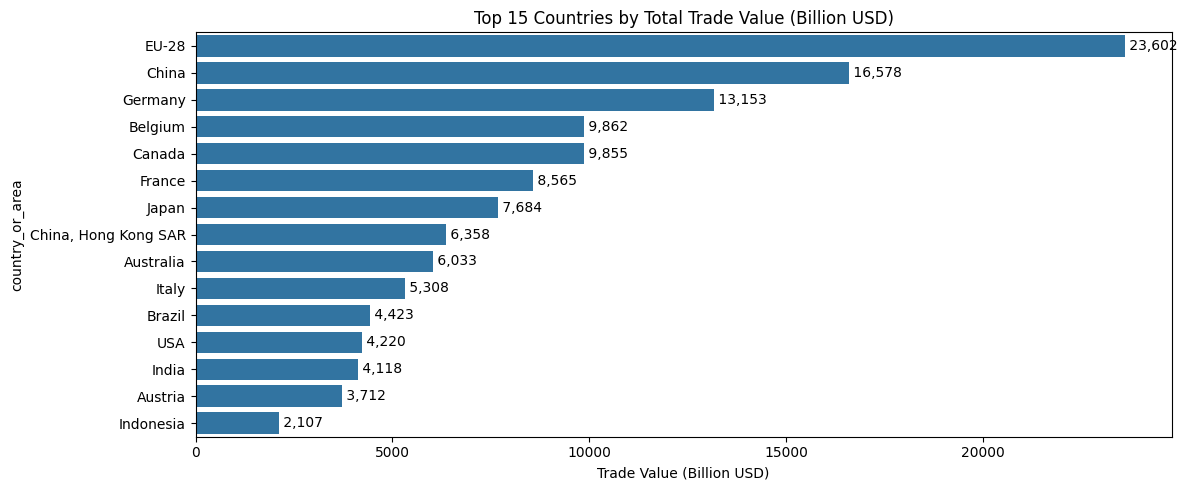

In [ ]:
# Top 15 countries :

plt.figure(figsize=(12,5))
top_countries = df.groupby('country_or_area')['trade_usd'].sum().sort_values(ascending=False).head(15) / 1e9

ax = sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title('Top 15 Countries by Total Trade Value (Billion USD)')
plt.xlabel('Trade Value (Billion USD)')

for i, v in enumerate(top_countries.values):
    ax.text(v, i, f' {v:,.0f}', va='center')

plt.tight_layout()
plt.show()

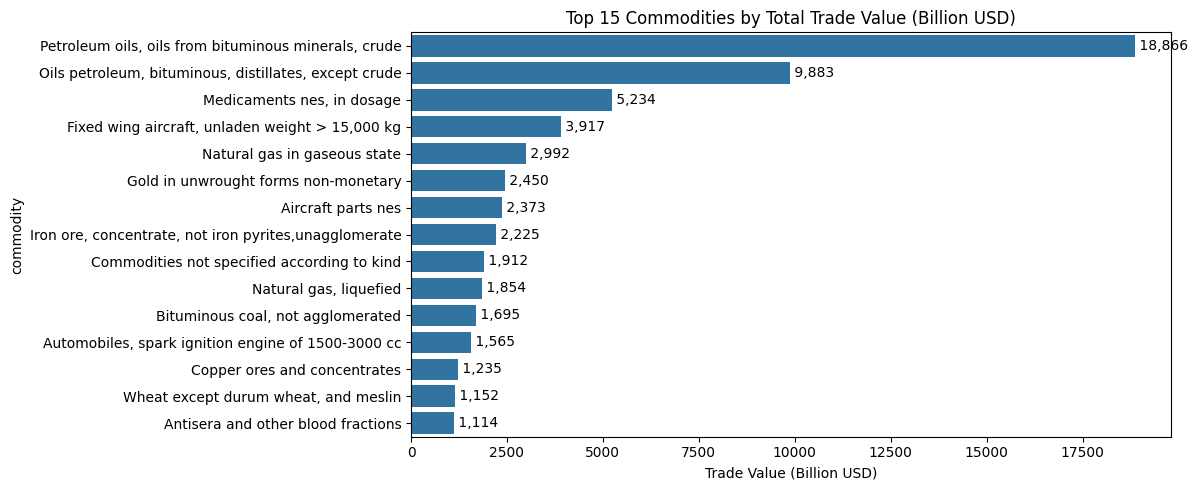

In [ ]:
# Top 15 Commodities:

plt.figure(figsize=(12,5))
top_commodities = df.groupby('commodity')['trade_usd'].sum().sort_values(ascending=False).head(15) / 1e9

ax = sns.barplot(x=top_commodities.values, y=top_commodities.index)
plt.title('Top 15 Commodities by Total Trade Value (Billion USD)')
plt.xlabel('Trade Value (Billion USD)')

for i, v in enumerate(top_commodities.values):
    ax.text(v, i, f' {v:,.0f}', va='center')

plt.tight_layout()
plt.show()

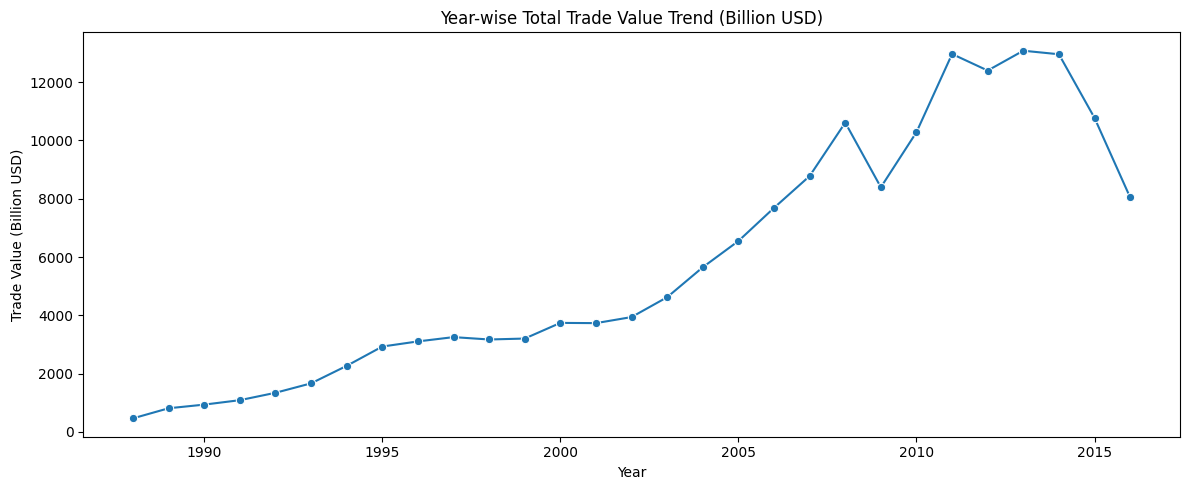

In [ ]:
# Year-wise Trend:

plt.figure(figsize=(12,5))
year_trend = df.groupby('year')['trade_usd'].sum() / 1e9

sns.lineplot(x=year_trend.index, y=year_trend.values, marker='o')
plt.title('Year-wise Total Trade Value Trend (Billion USD)')
plt.xlabel('Year')
plt.ylabel('Trade Value (Billion USD)')
plt.tight_layout()
plt.show()

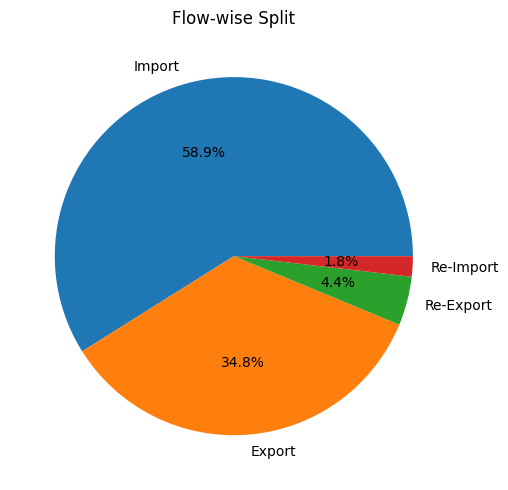

In [ ]:
# Flow-wise Split:

plt.figure(figsize=(12,5))
flow_split = df['flow'].value_counts()
plt.pie(flow_split.values, labels=flow_split.index, autopct='%1.1f%%')
plt.title('Flow-wise Split')
plt.tight_layout()
plt.show()

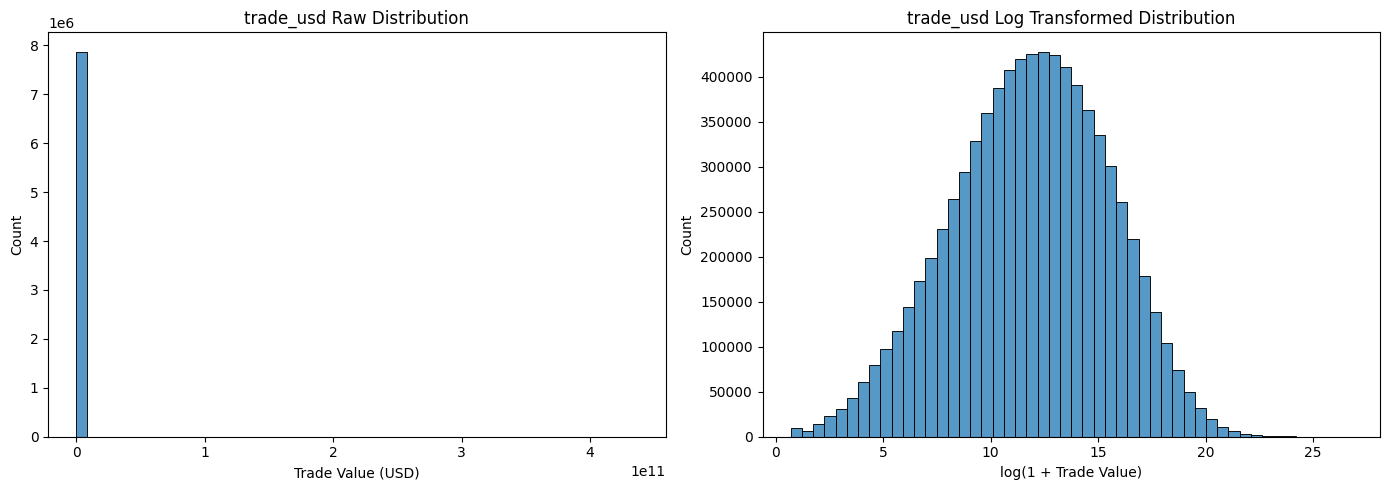

In [ ]:
plt.figure(figsize=(14, 5))

# Raw Distribution
plt.subplot(1, 2, 1)
sns.histplot(df['trade_usd'], bins=50)
plt.title('trade_usd Raw Distribution')
plt.xlabel('Trade Value (USD)')

# Log Transformed Distribution
plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df['trade_usd']), bins=50)
plt.title('trade_usd Log Transformed Distribution')
plt.xlabel('log(1 + Trade Value)')

plt.tight_layout()
plt.show()

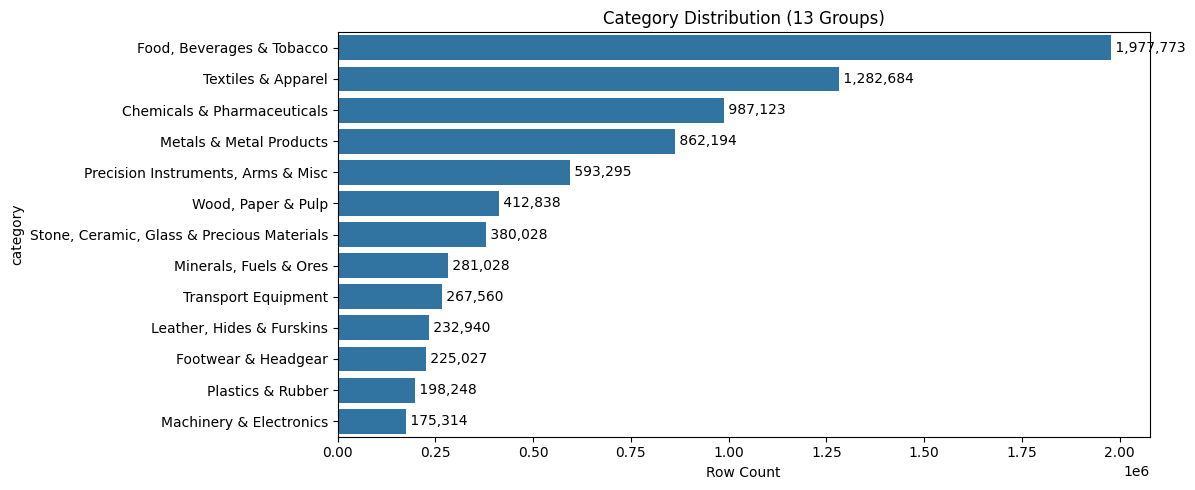

In [ ]:
# Category Distribution (13 groups):

plt.figure(figsize=(12,5))
category_counts = df['category'].value_counts()

ax = sns.barplot(x=category_counts.values, y=category_counts.index)
plt.title('Category Distribution (13 Groups)')
plt.xlabel('Row Count')

for i, v in enumerate(category_counts.values):
    ax.text(v, i, f' {v:,.0f}', va='center')

plt.tight_layout()
plt.show()

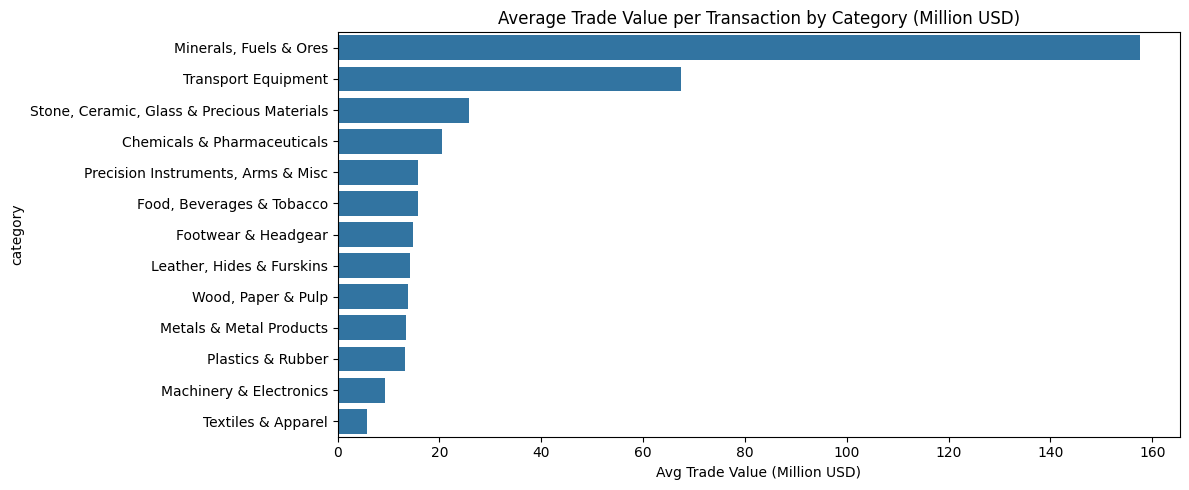

In [ ]:
# Category vs Average Trade Value
plt.figure(figsize=(12,5))
cat_avg = df.groupby('category')['trade_usd'].mean().sort_values(ascending=False) / 1e6

ax = sns.barplot(x=cat_avg.values, y=cat_avg.index)
plt.title('Average Trade Value per Transaction by Category (Million USD)')
plt.xlabel('Avg Trade Value (Million USD)')
plt.tight_layout()
plt.show()

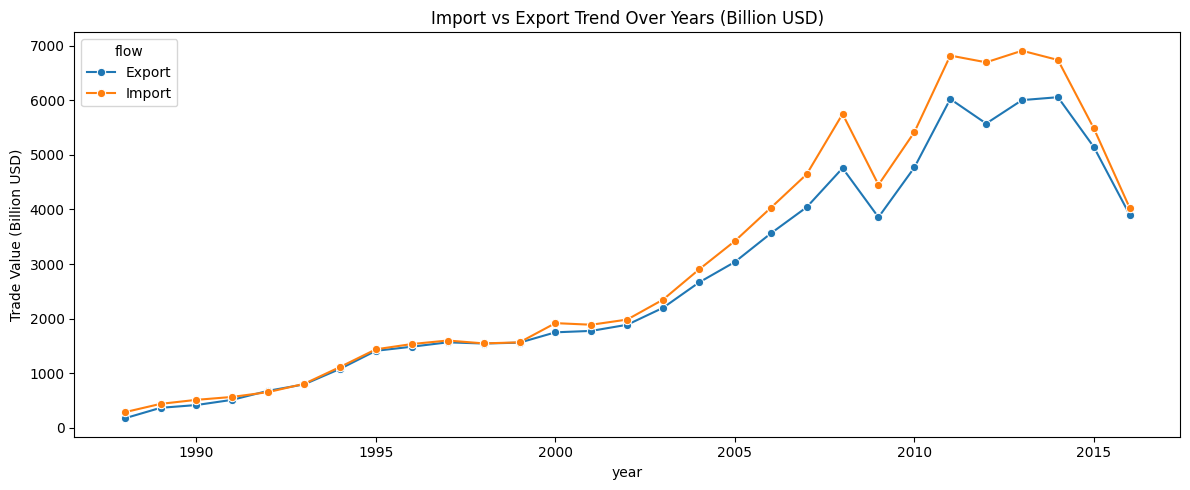

In [ ]:
# Import vs Export trend over years

plt.figure(figsize=(12,5))
flow_year = df[df['flow'].isin(['Import','Export'])].groupby(['year','flow'])['trade_usd'].sum().reset_index()
flow_year['trade_usd'] = flow_year['trade_usd']/1e9

sns.lineplot(data=flow_year, x='year', y='trade_usd', hue='flow', marker='o')
plt.title('Import vs Export Trend Over Years (Billion USD)')
plt.ylabel('Trade Value (Billion USD)')
plt.tight_layout()
plt.show()

In [ ]:
# Saving cleaned dataset

df.to_parquet('../dataset/trade_cleaned.parquet', index=False)
print("Saved! Final shape:", df.shape)
print(df.dtypes)

Saved! Final shape: (7876052, 13)
country_or_area     object
year                 int64
commodity           object
flow                object
trade_usd            int64
weight_kg          float64
quantity_name       object
quantity           float64
category            object
category_final      object
unit_price         float64
price_per_kg       float64
qty_per_kg         float64
dtype: object
